# 7단계 | Gemini 무료 티어 구조화 규격 추출
- 기존 06 입력·표 원문·DL 위치 후보와 07 Pydantic 스키마·단위·근거 검증을 재사용함
- 개발용 T55·TCJ·TPB의 등록 P/N 3개만 사용함. 평가 PDF와 정답 데이터 제외함
- gemini-3.1-flash-lite의 무료 입력·출력 및 구조화 출력 지원을 Google 공식 문서에서 확인함
- 프로젝트 루트 .env의 GEMINI_API_KEY만 읽음. 키 값은 출력하지 않음. 저장된 출력은 이전 실행 기록임.
- 모델의 무료 지원과 실제 키 프로젝트의 무료 상태는 별개임. Google AI Studio에서 같은 키의 Free Tier 및 결제 미연결을 확인하기 전에는 요청하지 않음
- 첫 P/N의 구조화 응답과 근거 검사를 통과한 경우에만 나머지 P/N을 순차 호출함. 자동 재시도·다른 모델·유료 경로 없음
- 참고: https://ai.google.dev/gemini-api/docs/pricing · https://ai.google.dev/gemini-api/docs/structured-output · https://ai.google.dev/gemini-api/docs/billing

In [1]:
from pathlib import Path
import base64
from collections import Counter
from importlib.metadata import version
from copy import deepcopy
import hashlib
import json
import os
import re
from unittest.mock import patch

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import pymupdf
import torch
from PIL import Image
from IPython.display import display
from pydantic import ValidationError

from table_detection import load_table_detector, load_structure_recognizer
from datasheet_analysis import (SPEC_FIELDS, PartExtraction, GEMINI_EXTRACTION_MODEL, EXTRACTION_PROMPT_VERSION,
    MAX_EXTRACTION_OUTPUT_TOKENS, read_gemini_api_key, gemini_free_tier_is_confirmed, gemini_sample_passes_gate,
    extract_document_source, select_extraction_evidence, estimate_extraction_budget, normalize_spec_value,
    validate_extraction, request_gemini_extraction, detect_page_regions, recognize_region_structure)

ROOT=Path.cwd()
parts=pd.read_csv(ROOT/'data/part_numbers.csv',dtype=str)
splits=pd.read_csv(ROOT/'data/dataset_split.csv',dtype=str).set_index('document_id')
bundle=json.loads((ROOT/'results/06_llm_input_samples.json').read_text(encoding='utf-8'))
documents={r['document_id']:r for r in bundle['documents']}
chosen_ids=('vishay_t55','kyocera_avx_tcj','panasonic_tpb')
targets=parts[parts.document_id.isin(chosen_ids)&parts.split.eq('dev')].drop_duplicates('document_id')
assert len(targets)==3 and set(targets.document_id)==set(chosen_ids)
for r in targets.itertuples():
    assert splits.loc[r.document_id,'split']==documents[r.document_id]['split']=='dev'
paths={d:ROOT/'data/datasheets'/documents[d]['filename'] for d in chosen_ids}
for doc,path in paths.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest()==documents[doc]['pdf_sha256']
api_key_present=bool(read_gemini_api_key())
free_tier_confirmed=gemini_free_tier_is_confirmed()
legacy_paths=('results/07_llm_extraction.json','results/07_llm_extraction_summary.csv',
    'results/07_llm_extraction_errors.csv','outputs/07_llm_spec_status.png','outputs/07_llm_extraction_errors.png')
previous_path=ROOT/legacy_paths[0]
legacy_archive=None
if previous_path.exists():
    previous=json.loads(previous_path.read_text(encoding='utf-8'))
    assert previous.get('requests_attempted')==0, '기존 실제 요청 기록이 있어 반복 실행 전에 별도 검토 필요함'
    if previous.get('provider')=='openai':
        assert previous.get('execution_mode')=='preflight_only'
        saved_files=[]
        for relative in legacy_paths:
            contents=(ROOT/relative).read_bytes()
            saved_files.append({'path':relative,'sha256':hashlib.sha256(contents).hexdigest(),
                'encoding':'base64','data':base64.b64encode(contents).decode('ascii')})
        legacy_archive={'provider':'openai','execution_mode':'preflight_only','files':saved_files}
    elif previous.get('provider')=='gemini':
        legacy_archive=previous.get('legacy_openai_preflight_archive')
    else:
        raise ValueError('기존 7단계 결과의 제공자를 확인할 수 없음')
print({'provider':'gemini','requested_model':GEMINI_EXTRACTION_MODEL,'sdk':version('google-genai'),
       'pydantic':version('pydantic'),'api_key_configured':api_key_present,
       'free_project_confirmed':free_tier_confirmed})
display(targets[['document_id','part_number']])

{'provider': 'gemini', 'requested_model': 'gemini-3.1-flash-lite', 'sdk': '3.0.0', 'pydantic': '2.14.3', 'api_key_configured': False, 'free_project_confirmed': False}


,document_id,part_number
2,vishay_t55,T55A226M2R5C0200
9,kyocera_avx_tcj,TCJU337M016R0050E
14,panasonic_tpb,4TPB68M


## 원문 근거 선정과 전송 규모
- 대상 P/N 행, 표 헤더와 전압 그룹, 시리즈 조건·주문 안내·각주 보존함. 제조사별 구조 후보 상태도 전달함
- 06 입력에 없던 TCJ 10~12쪽의 카테고리 제목과 서지 시험 문구를 개발용 원본에서 추가함. 카테고리 연결이나 배수 계산을 가정하지 않음
- TPB 미탐지 특성표는 병합 행 문맥을 보존함. 화면에 가려진 13개 단어는 전송 근거에서 제외함
- 지시문·입력·스키마의 UTF-8 바이트/4로 사전 토큰을 근사함. 실제 토큰은 Gemini 사용량 응답이 있는 경우에만 기록함

In [2]:
supplemental,_,_=extract_document_source(paths['kyocera_avx_tcj'],'kyocera_avx_tcj',[10,11,12],[])
prepared=[]
plans=[]
for target in targets.itertuples():
    d,pn=target.document_id,target.part_number
    item=select_extraction_evidence(bundle,d,pn,supplemental if d=='kyocera_avx_tcj' else None)
    prepared.append(item)
    old=next(s for s in bundle['samples'] if (s['document_id'],s['part_number'])==(d,pn))
    budget=estimate_extraction_budget(item)
    plans.append({'document_id':d,'part_number':pn,'pdf_pages':sorted({e['pdf_page'] for e in item['evidence']}),
        'source_excerpts':len(item['evidence']),
        'stage6_estimated_input_tokens':old['input_size']['estimated_tokens_utf8_bytes_div4'],
        **budget})
    assert budget['estimated_input_tokens_including_prompt_schema']<old['input_size']['estimated_tokens_utf8_bytes_div4']
    with pymupdf.open(paths[d]) as pdf:
        for entry in item['evidence']:
            page=pdf[entry['pdf_page']-1]
            raw=page.get_text('words',sort=False)
            stored=item['pages'][entry['pdf_page']]
            ids=entry['word_ids']
            assert set(ids).isdisjoint(stored['hidden_word_ids'])
            assert all([raw[i][4],*raw[i][:4],*raw[i][5:8]]==stored['words'][i] for i in ids)
            assert entry['text']==' '.join(raw[i][4] for i in ids)
    print(d,[(e['pdf_page'],e['label'],e['evidence_id']) for e in item['evidence']])
    print('등록 P/N 원문 행:',[e['text'] for e in item['evidence'] if e['label']=='exact_target_pn_row'])
    assert pn in next(e['text'] for e in item['evidence'] if e['label']=='exact_target_pn_row').split()
display(pd.DataFrame(plans))
print('입력 토큰 추정 합계:',sum(p['estimated_input_tokens_including_prompt_schema'] for p in plans))

vishay_t55 [(1, 'series_electrical_context', 'p1-e01'), (1, 'ordering_guide', 'p1-e02'), (1, 'series_technical_note', 'p1-e03'), (5, 'table_header', 'p5-e04'), (5, 'voltage_group', 'p5-e05'), (5, 'table_footnotes', 'p5-e06'), (15, 'performance_and_surge', 'p15-e07'), (15, 'test_conditions_footnote', 'p15-e08'), (5, 'exact_target_pn_row', 'p5-e09')]
등록 P/N 원문 행: ['22 A T55A226M2R5C0200 5.5 10 200 0.75 105 1000']
kyocera_avx_tcj [(1, 'ordering_guide', 'p1-e01'), (1, 'series_technical_context', 'p1-e02'), (6, 'table_header', 'p6-e03'), (10, 'category_heading', 'p10-e04'), (10, 'surge_test_conditions', 'p10-e05'), (11, 'category_heading', 'p11-e06'), (11, 'surge_test_conditions', 'p11-e07'), (12, 'category_heading', 'p12-e08'), (12, 'surge_test_conditions', 'p12-e09'), (6, 'exact_target_pn_row', 'p6-e10')]
등록 P/N 원문 행: ['TCJU337M016R0050E U 330 16 125 528 12 50 2800 2000 1300 700 1 3']
panasonic_tpb [(1, 'series_specification_table', 'p1-e01'), (1, 'ordering_marking_rules', 'p1-e02'), (1, 

,document_id,part_number,pdf_pages,source_excerpts,stage6_estimated_input_tokens,user_input_characters,estimated_input_tokens_including_prompt_schema,max_output_tokens
0,vishay_t55,T55A226M2R5C0200,"[1, 5, 15]",9,19022,15117,4973,2500
1,kyocera_avx_tcj,TCJU337M016R0050E,"[1, 6, 10, 11, 12]",10,14049,8264,3257,2500
2,panasonic_tpb,4TPB68M,[1],6,12418,9131,3451,2500


입력 토큰 추정 합계: 11681


## 스키마·단위·근거 검사
- 여섯 규격을 항상 요구함. found에 값·단위·페이지·근거·범위·출처 유형 필수임. 미확정 상태에는 값 없음
- 문서에 있는 십진수만 변환함. 범위·조건과 원본 값을 유지함. 단위가 다르면 명시적 배율을 적용함
- 원문과 숫자 일치만으로 검증 완료 처리하지 않음. 유일한 P/N·열 위치 및 헤더 근거가 있는 제한된 경우만 verified임
- 아래는 검사기 테스트이며 API 추출 건수·정확도에 포함하지 않음

In [3]:
assert normalize_spec_value('rated_voltage','2500','mV')['value']=='2.500'
assert normalize_spec_value('capacitance','470','nF')['value']=='0.470'
assert normalize_spec_value('esr','0.05','Ω')['value']=='50.00'
assert normalize_spec_value('tolerance','± 20','%')['value']=='±20'
assert normalize_spec_value('operating_temperature','−55 °C to +105 °C','°C','−55','+105')['min']=='-55'
try:
    normalize_spec_value('surge_voltage','1.3 × rated voltage','V')
except ValueError:
    pass
else:
    raise AssertionError('규격 전압 계산식을 스칼라로 허용함')

absent={'status':'not_found','value':None,'unit':None,'value_min':None,'value_max':None,
        'condition':None,'page':None,'scope':None,'source_type':None,'evidence_id':None,
        'evidence':None,'supporting_evidence':[],'reason':None}
probe=prepared[0]
slot=probe['direct_slots']['capacitance']
row=next(e for e in probe['evidence'] if e['evidence_id']==slot['row_evidence_id'])
header=next(e for e in probe['evidence'] if e['label']=='table_header')
unit='μF'
assert unit in header['text']
fixture={'part_number':probe['request']['part_number'],'specifications':{k:deepcopy(absent) for k in SPEC_FIELDS}}
fixture['specifications']['capacitance'].update(status='found',value=slot['text'],unit=unit,page=row['pdf_page'],
    scope='pn',source_type='table',evidence_id=row['evidence_id'],evidence=row['text'],
    supporting_evidence=[{'evidence_id':header['evidence_id'],'page':header['pdf_page'],'quote':header['text']}])
def cap_status(value):
    """검사기 시험 입력의 정전용량 근거 판정을 반환함."""
    return validate_extraction(PartExtraction.model_validate(value),probe)['capacitance']
assert cap_status(fixture)['verification_status']=='verified'
changed=deepcopy(fixture)
changed['specifications']['capacitance']['page']=999
assert 'evidence_page_or_id_mismatch' in cap_status(changed)['issues']
changed=deepcopy(fixture)
changed['specifications']['capacitance']['evidence']='not a source quote'
assert 'evidence_text_mismatch' in cap_status(changed)['issues']
changed=deepcopy(fixture)
changed['part_number']=prepared[1]['request']['part_number']
assert 'output_pn_mismatch' in cap_status(changed)['issues']
changed=deepcopy(fixture)
changed['specifications']['capacitance']['scope']='series'
assert cap_status(changed)['verification_status']=='unverifiable'
changed=deepcopy(fixture)
del changed['specifications']['surge_voltage']
try:
    PartExtraction.model_validate(changed)
except ValidationError:
    pass
else:
    raise AssertionError('누락된 규격을 허용함')
from google import genai
import httpx2
from tempfile import TemporaryDirectory

with TemporaryDirectory() as tmp:
    env_path=Path(tmp)/'.env'
    with patch('datasheet_analysis._GEMINI_DOTENV_PATH',env_path), patch(
        'google.genai.Client',side_effect=AssertionError('확인 없이 Gemini 클라이언트를 생성함')):
        with patch.dict(os.environ,{'GEMINI_API_KEY':'ignored-environment-fixture',
                                     'DATASHEET_GEMINI_FREE_TIER_KEY_SHA256':''}):
            assert request_gemini_extraction(probe)['error_type']=='missing_api_key'
        env_path.write_text('GEMINI_API_KEY=offline-fixture\n',encoding='utf-8')
        with patch.dict(os.environ,{'DATASHEET_GEMINI_FREE_TIER_KEY_SHA256':'wrong'}):
            assert request_gemini_extraction(probe)['error_type']=='free_project_tier_unconfirmed'

def mock_transport_handler(request):
    """네트워크 없이 SDK의 요청 구조와 429 경로만 확인함."""
    assert request.method=='POST' and request.url.host=='generativelanguage.googleapis.com'
    assert request.url.path.endswith('/'+GEMINI_EXTRACTION_MODEL+':generateContent')
    body=json.loads(request.content)
    generation=body['generationConfig']
    assert generation['responseMimeType']=='application/json'
    assert generation['maxOutputTokens']==MAX_EXTRACTION_OUTPUT_TOKENS
    assert len(generation['responseJsonSchema']['$defs']['ExtractedSpecifications']['required'])==6
    mock_calls.append(request.method)
    return httpx2.Response(429,json={'error':{'code':429,'message':'offline transport fixture',
                                            'status':'RESOURCE_EXHAUSTED'}})

real_client=genai.Client
def client_with_mock_transport(**kwargs):
    """실제 SDK에서 전송 계층만 로컬 검사로 대체함."""
    kwargs['http_options'].httpx_client=httpx2.Client(transport=httpx2.MockTransport(mock_transport_handler))
    return real_client(**kwargs)

mock_calls=[]
local_key='offline-fixture'
with TemporaryDirectory() as tmp:
    env_path=Path(tmp)/'.env'
    env_path.write_text(f'GEMINI_API_KEY={local_key}\n',encoding='utf-8-sig')
    with patch('datasheet_analysis._GEMINI_DOTENV_PATH',env_path), patch.dict(
        os.environ,{'DATASHEET_GEMINI_FREE_TIER_KEY_SHA256':hashlib.sha256(local_key.encode()).hexdigest()}):
        with patch('google.genai.Client',side_effect=client_with_mock_transport):
            mock_record=request_gemini_extraction(probe)
assert mock_calls==['POST'] and mock_record['error_type']=='quota_or_rate_limit'
assert not mock_record['response_received'] and not gemini_sample_passes_gate(mock_record)
print('Pydantic·단위·원문·P/N 검사 및 로컬 SDK 요청·429 무재시도 검사 통과함. 실제 응답 생성 없음')

Pydantic·단위·원문·P/N 검사 및 로컬 SDK 요청·429 무재시도 검사 통과함. 실제 응답 생성 없음


## 기존 DL·PDF 회귀 검사
- T55 5쪽의 기존 탐지·구조 좌표와 점수를 같은 커밋에서 다시 계산해 확인함. 실제 P/N 근거는 세 PDF의 원문 단어와 별도 대조함

In [4]:
torch.set_num_threads(min(4,os.cpu_count() or 1))
cache=ROOT/'.venv/model_cache'
pr,mo,de,_=load_table_detector(cache_dir=cache,local_files_only=True)
detector=(pr,mo,de)
pr,mo,de,_=load_structure_recognizer(cache_dir=cache,local_files_only=True)
recognizer=(pr,mo,de)
image,meta,regions,_=detect_page_regions(paths['vishay_t55'],5,detector)
prior=bundle['page_sources']['vishay_t55:p5']
assert len(regions)==len(prior['table_regions'])==1
for region,saved in zip(regions,prior['table_regions']):
    assert np.allclose(region['expanded_bbox_pdf'],saved['expanded_bbox_pdf'],atol=.05,rtol=0)
    assert abs(region['confidence']-saved['confidence'])<1e-6
    current=recognize_region_structure(image,meta,region,recognizer)['objects']
    previous=prior['row_column_candidates'][0]['objects']
    assert len(current)==len(previous)
    assert all(a['label']==b['label'] and abs(a['confidence']-b['confidence'])<1e-6 and
        np.allclose(a['bbox_pdf'],b['bbox_pdf'],atol=.05,rtol=0) for a,b in zip(current,previous))
print('기존 탐지·구조 좌표와 점수 일치함')

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-detection
Key                                                                         | Status     |  | 
----------------------------------------------------------------------------+------------+--+-
model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-structure-recognition
Key                                                                         | Status     |  | 
----------------------------------------------------------------------------+------------+--+-
model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


기존 탐지·구조 좌표와 점수 일치함


## 첫 표본 확인 후 순차 실행
- 키와 같은 프로젝트의 Free Tier 확인이 모두 있을 때만 첫 표본을 호출함
- 첫 응답에서 스키마·P/N·근거 검사를 통과한 경우 나머지 표본을 순차 처리함. 오류가 나면 이후 요청 중단함
- 호출 전 차단은 추출 실패 또는 not_found가 아님. 기존 OpenAI 미호출 기록은 Gemini 결과와 분리함
- 검증된 정답표 없음 확인함. 정확도 산출하지 않음

In [5]:
records=[]
stop_after_failure=False
for item in prepared:
    record=request_gemini_extraction(item,stop_after_failure=stop_after_failure)
    records.append(record)
    if record['request_attempted'] and not gemini_sample_passes_gate(record):
        stop_after_failure=True
display(pd.DataFrame(records)[['document_id','part_number','execution_status','request_attempted',
    'response_received','error_type','model','input_tokens','output_tokens','processing_seconds']])
summary_rows,error_rows=[],[]
for record in records:
    common={k:record[k] for k in ('document_id','part_number','execution_status')}
    common['manufacturer']=documents[record['document_id']]['manufacturer']
    if record['error_type']:
        error_rows.append({**common,'specification':None,'error_type':record['error_type'],
            'cause':'호출 전 차단' if not record['request_attempted'] else 'API 요청 또는 응답 처리 오류',
            'review_status':'observed','source_comparison':None})
    for field in SPEC_FIELDS:
        item=(record['extraction'] or {}).get('specifications',{}).get(field,{})
        check=(record['verification'] or {}).get(field,{})
        summary_rows.append({**common,'specification':field,'extraction_status':item.get('status'),
            'verification_status':check.get('verification_status'),'value':item.get('value'),'unit':item.get('unit'),
            'value_min':item.get('value_min'),'value_max':item.get('value_max'),'condition':item.get('condition'),
            'pdf_page':item.get('page'),'scope':item.get('scope'),'source_type':item.get('source_type'),
            'evidence_id':item.get('evidence_id'),'evidence':item.get('evidence'),
            'normalized':json.dumps(check['normalized'],ensure_ascii=False) if check.get('normalized') else None})
        for issue in check.get('issues',[]):
            if issue=='no_confirmed_value_to_check':
                continue
            source_evidence=next((e for p in prepared if p['request']['part_number']==record['part_number']
                for e in p['evidence'] if e['evidence_id']==item.get('evidence_id')),None)
            error_rows.append({**common,'specification':field,'error_type':issue,
                'cause':'자동 검증에서 불일치 확인 또는 연결 미확인',
                'review_status':check['verification_status'],
                'source_comparison':None if source_evidence is None else json.dumps({
                    'pdf_page':source_evidence['pdf_page'],'actual_excerpt':source_evidence['text'],
                    'reported_quote':item.get('evidence')},ensure_ascii=False)})
summary=pd.DataFrame(summary_rows)
error_columns=['document_id','manufacturer','part_number','execution_status','specification','error_type','cause','review_status','source_comparison']
errors=pd.DataFrame(error_rows,columns=error_columns)
actual_attempts=sum(r['request_attempted'] for r in records)
actual_responses=sum(r['response_received'] for r in records)
actual_parsed=sum(r['extraction'] is not None for r in records)
assert actual_attempts<=3
if not free_tier_confirmed or not api_key_present:
    assert actual_attempts==actual_responses==actual_parsed==0
    assert summary.extraction_status.isna().all() and summary.verification_status.isna().all()
display(summary)
display(errors[['document_id','part_number','specification','error_type','review_status']])

,document_id,part_number,execution_status,request_attempted,response_received,error_type,model,input_tokens,output_tokens,processing_seconds
0,vishay_t55,T55A226M2R5C0200,blocked,False,False,missing_api_key,None,None,None,None
1,kyocera_avx_tcj,TCJU337M016R0050E,blocked,False,False,missing_api_key,None,None,None,None
2,panasonic_tpb,4TPB68M,blocked,False,False,missing_api_key,None,None,None,None


,document_id,part_number,execution_status,manufacturer,specification,extraction_status,verification_status,value,unit,value_min,value_max,condition,pdf_page,scope,source_type,evidence_id,evidence,normalized
0,vishay_t55,T55A226M2R5C0200,blocked,Vishay,rated_voltage,None,None,None,None,None,None,None,None,None,None,None,None,None
1,vishay_t55,T55A226M2R5C0200,blocked,Vishay,surge_voltage,None,None,None,None,None,None,None,None,None,None,None,None,None
2,vishay_t55,T55A226M2R5C0200,blocked,Vishay,capacitance,None,None,None,None,None,None,None,None,None,None,None,None,None
3,vishay_t55,T55A226M2R5C0200,blocked,Vishay,tolerance,None,None,None,None,None,None,None,None,None,None,None,None,None
4,vishay_t55,T55A226M2R5C0200,blocked,Vishay,esr,None,None,None,None,None,None,None,None,None,None,None,None,None
5,vishay_t55,T55A226M2R5C0200,blocked,Vishay,operating_temperature,None,None,None,None,None,None,None,None,None,None,None,None,None
6,kyocera_avx_tcj,TCJU337M016R0050E,blocked,KYOCERA AVX,rated_voltage,None,None,None,None,None,None,None,None,None,None,None,None,None
7,kyocera_avx_tcj,TCJU337M016R0050E,blocked,KYOCERA AVX,surge_voltage,None,None,None,None,None,None,None,None,None,None,None,None,None
8,kyocera_avx_tcj,TCJU337M016R0050E,blocked,KYOCERA AVX,capacitance,None,None,None,None,None,None,None,None,None,None,None,None,None
9,kyocera_avx_tcj,TCJU337M016R0050E,blocked,KYOCERA AVX,tolerance,None,None,None,None,None,None,None,None,None,None,None,None,None


,document_id,part_number,specification,error_type,review_status
0,vishay_t55,T55A226M2R5C0200,None,missing_api_key,observed
1,kyocera_avx_tcj,TCJU337M016R0050E,None,missing_api_key,observed
2,panasonic_tpb,4TPB68M,None,missing_api_key,observed


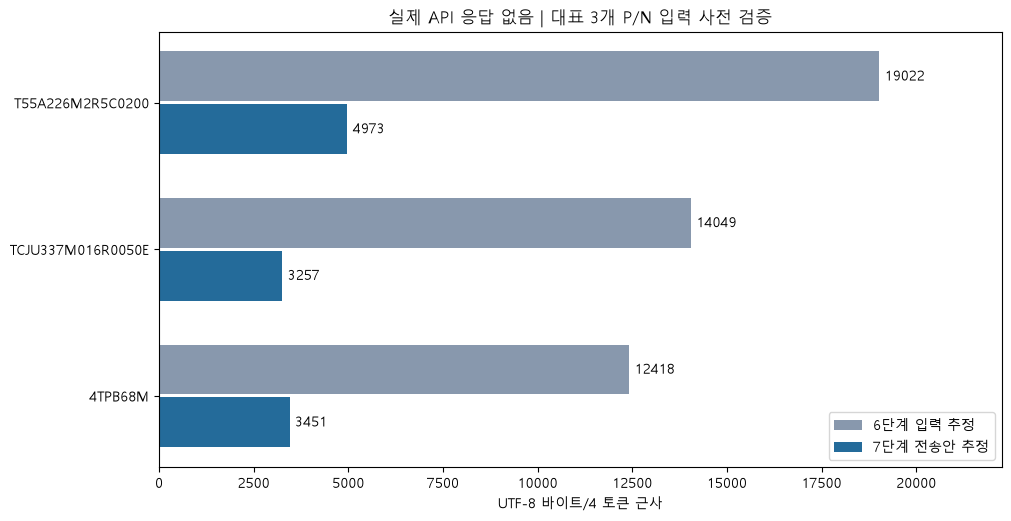

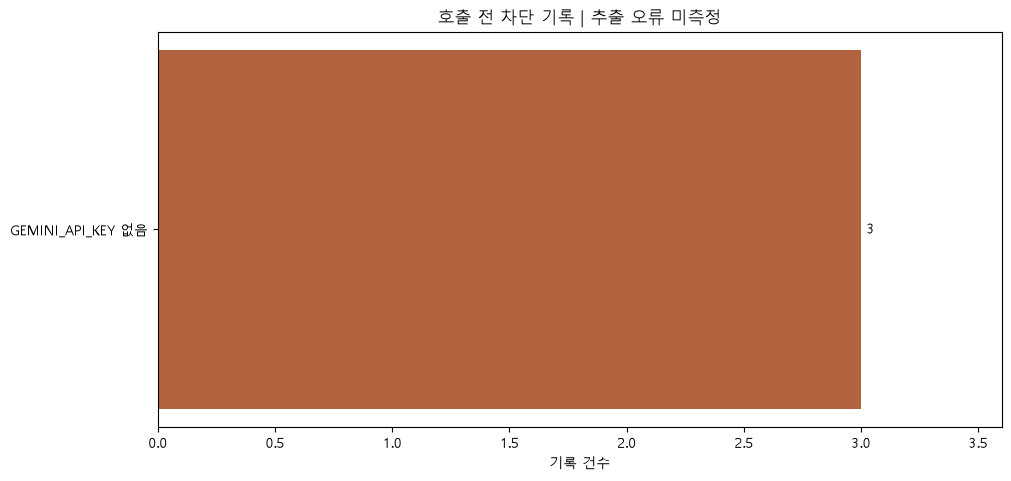

In [6]:
font_path=Path('C:/Windows/Fonts/malgun.ttf')
assert font_path.is_file()
font_manager.fontManager.addfont(str(font_path))
plt.rcParams.update({'font.family':font_manager.FontProperties(fname=str(font_path)).get_name(),
                     'axes.unicode_minus':False})
status_png=ROOT/'outputs/07_llm_spec_status.png'
errors_png=ROOT/'outputs/07_llm_extraction_errors.png'
if actual_parsed:
    fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
    names={'rated_voltage':'정격전압','surge_voltage':'서지전압','capacitance':'정전용량',
        'tolerance':'허용오차','esr':'ESR','operating_temperature':'동작온도'}
    for ax,col,keys,title in [
        (axes[0],'extraction_status',('found','not_found','ambiguous','extraction_error'),'추출 상태'),
        (axes[1],'verification_status',('verified','failed','unverifiable'),'자동 근거 검사')]:
        counts=summary.groupby(['specification',col]).size().unstack(fill_value=0).reindex(
            index=SPEC_FIELDS,columns=keys,fill_value=0)
        counts.index=[names[k] for k in counts.index]
        counts.plot.bar(ax=ax,rot=0)
        for bars in ax.containers:
            ax.bar_label(bars,padding=1,fontsize=8)
        ax.set(title=title,ylabel='건수',xlabel='')
    fig.suptitle(f'실제 구조화 응답 {actual_parsed}개 P/N | 자동 검사 결과이며 정확도 아님')
else:
    fig,ax=plt.subplots(figsize=(10,5.1),layout='constrained')
    y=np.arange(len(plans))
    old=[p['stage6_estimated_input_tokens'] for p in plans]
    new=[p['estimated_input_tokens_including_prompt_schema'] for p in plans]
    for offset,data,label,color in [(-.18,old,'6단계 입력 추정','#8898ad'),(.18,new,'7단계 전송안 추정','#246b9a')]:
        bars=ax.barh(y+offset,data,height=.34,label=label,color=color)
        ax.bar_label(bars,fmt='%.0f',padding=4)
    ax.set_yticks(y,[p['part_number'] for p in plans])
    ax.invert_yaxis()
    ax.set_xlim(0,max(old)*1.17)
    ax.set(xlabel='UTF-8 바이트/4 토큰 근사',title='실제 API 응답 없음 | 대표 3개 P/N 입력 사전 검증')
    ax.legend()
fig.savefig(status_png,dpi=180)
plt.show()
plt.close(fig)

fig,ax=plt.subplots(figsize=(10,4.7),layout='constrained')
observed=errors.error_type.value_counts()
if observed.empty:
    ax.axis('off')
    ax.text(.5,.52,'관찰된 오류 없음',ha='center',va='center',fontsize=17,transform=ax.transAxes)
else:
    names={'missing_api_key':'GEMINI_API_KEY 없음','free_project_tier_unconfirmed':'프로젝트 무료 티어 미확인',
        'previous_sample_not_validated':'앞 표본 근거 검증 미통과','quota_or_rate_limit':'무료 할당량 또는 속도 제한',
        'output_pn_mismatch':'P/N 불일치','evidence_text_mismatch':'원문 인용 불일치',
        'invalid_unit_value_or_range':'단위·값·범위 오류',
        'esr_measurement_frequency_missing':'ESR 측정 주파수 누락'}
    labels=[names.get(k,k) for k in observed.index]
    bars=ax.barh(labels,observed.values,color='#b2623d')
    ax.bar_label(bars,padding=4)
    ax.set_xlim(0,max(observed)*1.2)
    ax.invert_yaxis()
    ax.set_xlabel('기록 건수')
ax.set_title('호출 전 차단 기록 | 추출 오류 미측정' if actual_attempts==0 else
             '실제 실행에서 관찰한 오류와 자동 검토 항목')
fig.savefig(errors_png,dpi=180)
plt.show()
plt.close(fig)

## 저장과 최종 검증
- JSON에는 응답과 사전 실행 기록을 분리함. 호출이 없으면 responses는 빈 배열임
- CSV에는 대상 P/N별 여섯 규격의 실행 여부를 기록함. 미실행 값은 채우지 않음
- 결과와 원문 파일을 재읽어 확인함. 모델 로드 및 Jupyter 경고와 API 응답 오류를 구분함
- OpenAI 미호출 JSON·CSV·PNG 원본 5개를 Base64와 SHA-256으로 JSON 안에 별도 보존함

In [7]:
json_path=ROOT/'results/07_llm_extraction.json'
summary_path=ROOT/'results/07_llm_extraction_summary.csv'
errors_path=ROOT/'results/07_llm_extraction_errors.csv'
payload={'stage':'07_llm_extraction','execution_mode':'live' if actual_attempts else 'preflight_only',
    'provider':'gemini','requested_model':GEMINI_EXTRACTION_MODEL,'sdk_version':version('google-genai'),
    'prompt_version':EXTRACTION_PROMPT_VERSION,
    'settings':{'structured_outputs':True,'response_mime_type':'application/json','max_attempts':3,
        'max_retries':0,'max_output_tokens_per_request':MAX_EXTRACTION_OUTPUT_TOKENS},
    'free_tier':{'model_public_free_input_output':True,'project_confirmed':free_tier_confirmed,
        'key_configured':api_key_present,'actual_cost_usd':0 if not actual_attempts else None,
        'billing_data_available':False},'legacy_openai_preflight_archive':legacy_archive,
    'requests_planned':len(prepared),'requests_attempted':actual_attempts,'responses_received':actual_responses,
    'parsed_responses':actual_parsed,'request_plans':plans,
    'execution_records':[{k:v for k,v in r.items() if k not in {'extraction','verification'}} for r in records],
    'responses':[r for r in records if r['response_received']],
    'source_excerpts':[{'document_id':p['request']['document_id'],'part_number':p['request']['part_number'],
        'evidence':p['evidence']} for p in prepared],
    'accuracy_evaluated':False,'accuracy':None}
json_path.write_text(json.dumps(payload,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
summary.to_csv(summary_path,index=False,encoding='utf-8-sig')
errors.to_csv(errors_path,index=False,encoding='utf-8-sig')
assert json.loads(json_path.read_text(encoding='utf-8'))==payload
assert len(pd.read_csv(summary_path))==len(prepared)*len(SPEC_FIELDS)
assert list(pd.read_csv(errors_path).columns)==error_columns
for p in (status_png,errors_png):
    with Image.open(p) as image:
        assert image.format=='PNG'
        image.verify()
display({'local_verification':'passed','execution_mode':payload['execution_mode'],
    'planned_pn':len(prepared),'actual_requests':actual_attempts,'actual_responses':actual_responses,
    'parsed_pn':actual_parsed,'input_tokens_estimate':sum(p['estimated_input_tokens_including_prompt_schema'] for p in plans),
    'free_project_confirmed':free_tier_confirmed,'actual_cost_usd':payload['free_tier']['actual_cost_usd'],
    'actual_usage_reported':any(r['input_tokens'] is not None for r in records),
    'accuracy_evaluated':False,'ground_truth_status':'verified_ground_truth_not_available'})

{'local_verification': 'passed',
 'execution_mode': 'preflight_only',
 'planned_pn': 3,
 'actual_requests': 0,
 'actual_responses': 0,
 'parsed_pn': 0,
 'input_tokens_estimate': 11681,
 'free_project_confirmed': False,
 'actual_cost_usd': 0,
 'actual_usage_reported': False,
 'accuracy_evaluated': False,
 'ground_truth_status': 'verified_ground_truth_not_available'}